# Preprocesamiento y variables: ¿cómo elegimos cada decisión?

**Objetivo.** Documentar **con evidencia** cómo se eligió cada preprocesamiento, y probar empíricamente las decisiones que hasta ahora se habían tomado por criterio o por la literatura. Además, probar features de fuerza de equipo con memoria larga y medir la estabilidad de las variables entre temporadas (PSI).

**Cómo se eligió cada preprocesamiento** (resumen; el detalle está en los Pasos siguientes):

| Decisión | Criterio de elección | Evidencia |
|---|---|---|
| Descartar columnas post-partido (goles, tiros, tarjetas del propio partido) | **Leakage**: no se conocen antes del partido | lógica, `02_feature.ipynb` Paso 3 |
| No usar cuotas de cierre como feature | **Leakage**: se publican minutos antes del partido | lógica, `06_mercado.ipynb` Paso 6 |
| Forma con `shift(1)` y prior de liga estrictamente anterior a la fecha | **Leakage temporal** | verificación independiente (600 comprobaciones), `02_feature.ipynb` Paso 2 |
| No imputar estadísticas ausentes (F1 sin NaN / F2 con NaN) | **Calidad de datos**: el patrón de NaN es de la fuente, no del azar | `01_eda.ipynb` (limpieza) y `02_feature.ipynb` Paso 2b |
| Cuotas → probabilidades normalizadas → consenso → logit | **Empírico + teoría** | **Paso 1** de este notebook |
| Escalado (estandarización) para LR/SVM/MLP, ninguno para árboles | **Regla de Zheng cap. 2** (sensibilidad a la escala) | **Paso 2** |
| Valores faltantes: nativos en árboles; sin las columnas en F1 | **Empírico** | **Paso 3** |
| Transformaciones de asimetría (log, Yeo-Johnson), *winsorizing* | **Empírico** | **Paso 4** |
| Binning/WOE (Siddiqi) frente a variable continua | **Empírico** | **Paso 5** |
| Ventana de forma de 5 partidos | **Convención** (no probada) → se prueba aquí | **Paso 6** |
| Poda por correlación > 0.95 | **Redundancia**, sin mirar el target (Zheng cap. 2) | `02_feature.ipynb` Paso 5 |
| Plantilla como diferencia local − visitante | **Criterio** (ventaja neta) → se prueba normalizar por liga y temporada | **Paso 6** |

**Principio de comparación.** Cada alternativa se evalúa con la **misma validación temporal expansiva** de `04_modelo.ipynb` (8 folds, 2018/19–2025/26), con el log loss como métrica y con **intervalos por bloques** (temporada–semana) para la diferencia respecto a la opción vigente. Una alternativa solo reemplaza a la vigente si la mejora es consistente (signo en la mayoría de folds e IC que excluye 0); en caso contrario se mantiene la más simple.

**Convención.** Cada celda de código va precedida por una de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos y qué decidimos).

**Referencias.** Zheng & Casari caps. 2, 4, 5 y 6; Siddiqi cap. 10 (WOE/IV, binning) y cap. 12 (índice de estabilidad); ISLP cap. 5.

## Paso 0 — Carga y utilidades de evaluación

**Qué vamos a hacer.** Cargar los datos y definir tres utilidades que se reutilizan:

- `cv_proba`: validación temporal expansiva (entrena con las temporadas anteriores, predice la temporada del fold) con una máscara opcional de filas válidas.
- `loss_vec`: pérdida logarítmica por partido, para poder comparar alternativas **partido a partido**.
- `comparar`: diferencia pareada entre dos alternativas con IC por **bootstrap de bloques** `(temporada, semana)` y número de folds en que mejora.

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import (StandardScaler, RobustScaler, QuantileTransformer, PowerTransformer, MinMaxScaler, FunctionTransformer)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import log_loss, roc_auc_score

warnings.filterwarnings('ignore')
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv')
odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json'))
F1, F2 = fs['F1_sin_nan'], fs['F2_completo']
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy()
seas = df['Season'].to_numpy()
FOLDS = [s for s in sorted(np.unique(seas)) if s >= 1819]
EV = seas >= 1819
MKT = ['MKT_logit', 'MKT_pD', 'MKT_margin']
SQ = ['DIF_sq_top11', 'HomeTeam_sq_top11_mean']
FORMA = [f for f in F1 if f.startswith(('H_', 'A_'))]

fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
bloque = pd.factorize(df['Season'].astype(str) + '-' + fechas.dt.isocalendar().week.astype(str).to_numpy())[0]
rng = np.random.default_rng(11)

def cv_proba(fab, X, valid=None):
    Xn = X.to_numpy(float) if hasattr(X, 'to_numpy') else X
    valid = np.ones(len(y), bool) if valid is None else valid
    Pm = np.full((len(y), 3), np.nan)
    for s in FOLDS:
        tr, va = (seas < s) & valid, (seas == s) & valid
        Pm[va] = fab().fit(Xn[tr], y[tr]).predict_proba(Xn[va])
    return Pm

def loss_vec(Pm):
    out = np.full(len(y), np.nan); ok = ~np.isnan(Pm[:, 0])
    out[ok] = -np.log(np.clip(Pm[ok, y[ok]], 1e-9, 1)); return out

def comparar(la, lb, B=1000):
    """Diferencia pareada la - lb (negativo = la es MEJOR) en las filas donde ambas existen; IC por bloques."""
    ok = ~np.isnan(la) & ~np.isnan(lb); d = (la - lb)[ok]; b = bloque[ok]
    cod, K = pd.factorize(b)[0], len(np.unique(b))
    sm = np.bincount(cod, weights=d, minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    ix = rng.integers(0, K, (B, K)); bs = sm[ix].sum(1) / cn[ix].sum(1)
    fo = pd.Series(d).groupby(seas[ok]).mean()
    p = float(max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / B))
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), ic=f'[{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]', folds_mejora=f'{int((fo < 0).sum())}/{len(fo)}',
                signif=bool(np.percentile(bs, 97.5) < 0 or np.percentile(bs, 2.5) > 0), n=int(ok.sum()), p=p)

lr = lambda C=1.0: (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
print('filas:', len(df), '| folds:', FOLDS, '| bloques:', len(np.unique(bloque)))

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia; verde/rojo = el IC 95% excluye 0)'):
    """Delta con IC: verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible; la referencia (delta 0 sin IC) va en negro."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0)
        c = 'black' if ref else ('tab:green' if h < 0 else 'tab:red' if l > 0 else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(f'{d:+.4f}', (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.15)

filas: 36119 | folds: [np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)] | bloques: 494


**Qué encontramos.** 36,119 partidos, 8 folds de evaluación y 494 bloques `(temporada, semana)` en todo el dataset (326 de ellos contienen partidos de evaluación).

**Qué significa para nuestro caso.** Cada alternativa se juzga con la misma vara que el modelo final, así que "no mejora" significa realmente que no importa para nuestro problema.

**Decisión.** Todas las alternativas de los pasos siguientes se miden con estas utilidades, de modo que las diferencias sean comparables.

## Paso 1 — ¿Cómo convertir las cuotas en una feature?

**Qué vamos a hacer.** Comparar siete representaciones de la misma información (cuotas de apertura) con una regresión logística estandarizada:

| Variante | Qué es |
|---|---|
| `B365 cuotas crudas` | `o_H, o_D, o_A` tal cual |
| `B365 1/o` | probabilidad implícita **sin** quitar el margen |
| `B365 proporcional` | `p = (1/o)/Σ(1/o)` |
| `B365 potencia` | `p = (1/o)^k` con `Σp = 1` (reparte el margen distinto entre favoritos y longshots) |
| `B365 logit` | `ln(pH/pA)`, `pD`, margen (proporcional) |
| `Pinnacle logit` | igual, con la casa de menor margen |
| `Consenso (vigente)` | promedio de cuatro casas → `MKT_logit`, `MKT_pD`, `MKT_margin` |

**Por qué.** Zheng cap. 2: antes de elegir una transformación hay que preguntarse si importa la magnitud, la escala y la distribución. Las cuotas decimales son muy asimétricas (1.1 a 30+); las probabilidades están acotadas; el logit las vuelve lineales en log-odds. Para que la comparación sea justa se evalúa **solo** en las filas con B365 y Pinnacle observadas.

filas con B365 y Pinnacle observadas: 34428 de 36119 | de evaluacion: 22575


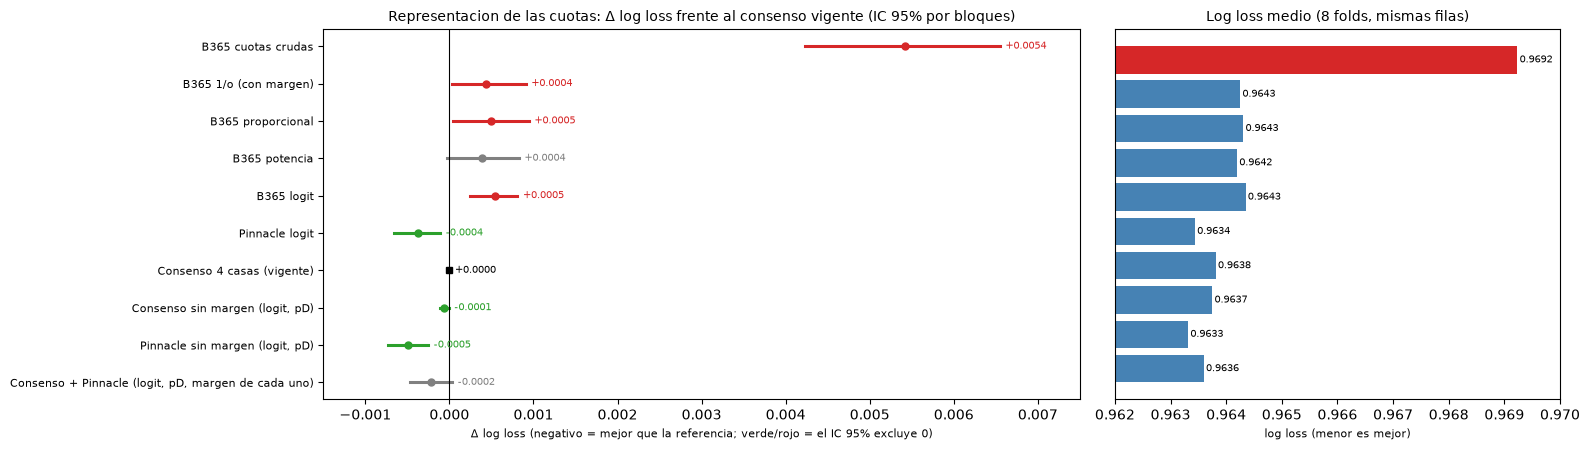

In [2]:
ms = pd.read_csv(DATA + 'matches_sq.csv', usecols=['Season', 'Date', 'HomeTeam', 'AwayTeam', 'B365H', 'B365D', 'B365A', 'PSH', 'PSD', 'PSA'])
o2 = df[['Season', 'Date', 'HomeTeam', 'AwayTeam']].merge(ms, on=['Season', 'Date', 'HomeTeam', 'AwayTeam'], how='left', validate='one_to_one')
B = o2[['B365H', 'B365D', 'B365A']].to_numpy(float); PS = o2[['PSH', 'PSD', 'PSA']].to_numpy(float)
valid = ~np.isnan(B).any(1) & ~np.isnan(PS).any(1)
print('filas con B365 y Pinnacle observadas:', int(valid.sum()), 'de', len(df), '| de evaluacion:', int((valid & EV).sum()))

def probs(O, metodo):
    inv = 1.0 / O
    if metodo == 'prop': return inv / inv.sum(1, keepdims=True)
    k_lo, k_hi = np.ones(len(O)), 4 * np.ones(len(O))
    for _ in range(60):
        k = (k_lo + k_hi) / 2; f = (inv ** k[:, None]).sum(1)
        k_lo, k_hi = np.where(f > 1, k, k_lo), np.where(f > 1, k_hi, k)
    return inv ** ((k_lo + k_hi) / 2)[:, None]
def logit_feat(O, metodo='prop'):
    p = probs(O, metodo); m = (1 / O).sum(1) - 1
    return np.c_[np.log(p[:, 0] / p[:, 2]), p[:, 1], m]

VAR = {'B365 cuotas crudas': B, 'B365 1/o (con margen)': 1 / B, 'B365 proporcional': probs(B, 'prop'), 'B365 potencia': probs(B, 'pot'),
       'B365 logit': logit_feat(B), 'Pinnacle logit': logit_feat(PS), 'Consenso 4 casas (vigente)': df[MKT].to_numpy(float),
       'Consenso sin margen (logit, pD)': df[['MKT_logit', 'MKT_pD']].to_numpy(float), 'Pinnacle sin margen (logit, pD)': logit_feat(PS)[:, :2],
       'Consenso + Pinnacle (logit, pD, margen de cada uno)': np.c_[df[MKT].to_numpy(float), logit_feat(PS)]}
LOSS_C = {}
filas = []
for nom, X in VAR.items():
    Pm = cv_proba(lr(), X, valid); LOSS_C[nom] = loss_vec(Pm)
    filas.append(dict(variante=nom, log_loss=float(np.nanmean(LOSS_C[nom][EV & valid])), acc=float((Pm[EV & valid].argmax(1) == y[EV & valid]).mean())))
t1 = pd.DataFrame(filas).set_index('variante')
ref = LOSS_C['Consenso 4 casas (vigente)']
rows = []
for nom in VAR:
    c = comparar(LOSS_C[nom], ref) if nom != 'Consenso 4 casas (vigente)' else dict(delta=0.0, lo=0.0, hi=0.0, folds_mejora='-', signif=False)
    rows.append(dict(variante=nom, delta=c['delta'], lo=c['lo'], hi=c['hi'], folds=c['folds_mejora']))
t1 = t1.join(pd.DataFrame(rows).set_index('variante'))
fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.7, 1]})
forest(axs[0], list(t1.index), t1.delta.to_numpy(), t1.lo.to_numpy(), t1.hi.to_numpy(), 'Representacion de las cuotas: Δ log loss frente al consenso vigente (IC 95% por bloques)')
axs[0].set_xlim(-0.0015, 0.0075)
axs[1].barh(range(len(t1))[::-1], t1.log_loss, color=['tab:red' if v > 0.968 else 'steelblue' for v in t1.log_loss]); axs[1].set_xlim(0.962, 0.970); axs[1].set_yticks([])
for yi, v in zip(range(len(t1))[::-1], t1.log_loss): axs[1].text(v + 0.00004, yi, f'{v:.4f}', va='center', fontsize=7)
axs[1].set_title('Log loss medio (8 folds, mismas filas)', fontsize=10); axs[1].set_xlabel('log loss (menor es mejor)', fontsize=8)
plt.tight_layout(); plt.show()

**Qué encontramos.** 34,428 partidos tienen B365 y Pinnacle observadas (22,575 de evaluación). Log loss medio de la LR en esas filas:

| Variante | Log loss | Δ vs vigente | IC 95% (bloques) | Folds en que mejora |
|---|---|---|---|---|
| B365 cuotas crudas | 0.9692 | **+0.0054** | [+0.0042, +0.0065] | 0/8 |
| B365 1/o (con margen) | 0.9643 | +0.0004 | [+0.0000, +0.0009] | 2/8 |
| B365 proporcional | 0.9643 | +0.0005 | [+0.0000, +0.0009] | 2/8 |
| B365 potencia | 0.9642 | +0.0004 | [−0.0000, +0.0008] | 2/8 |
| B365 logit | 0.9643 | +0.0005 | [+0.0002, +0.0008] | 1/8 |
| Pinnacle logit | 0.9634 | −0.0004 | [−0.0007, −0.0001] | 6/8 |
| **Consenso 4 casas (vigente)** | **0.9638** | — | — | — |
| Consenso sin margen (logit, pD) | 0.9637 | −0.0001 | [−0.0001, −0.0000] | 5/8 |
| Pinnacle sin margen (logit, pD) | **0.9633** | −0.0005 | [−0.0007, −0.0003] | 7/8 |
| Consenso + Pinnacle | 0.9636 | −0.0002 | [−0.0005, +0.0000] | 6/8 |

1. **Pasar de cuotas decimales a probabilidades importa mucho** (+0.0054 las cuotas crudas, 0/8 folds): es la única transformación con un efecto claro, y confirma la regla de Zheng cap. 2 (las magnitudes de las cuotas son muy asimétricas, de 1.1 a 30+).
2. **Una vez en escala de probabilidad, la forma exacta casi no importa:** `1/o`, proporcional, potencia y logit difieren en ≤ 0.0001 entre sí. La normalización por potencia (que reparte el margen distinto) no cambia nada, coherente con `06_mercado.ipynb` Paso 4.
3. **El consenso de cuatro casas es ligeramente mejor que una sola casa de apuestas común** (B365: +0.0005), pero **Pinnacle sola es mejor que el consenso** (−0.0004 con margen, −0.0005 sin margen; mejora en 6–7 de 8 folds). Pinnacle es la casa de menor margen y más precisa; promediarla con casas peores la diluye. Es una mejora real pero **pequeña** (menos de la mitad de lo que la LR ya mejora al mercado crudo).
4. **Quitar `MKT_margin` mejora levemente** (−0.0001 en el consenso, −0.0005 en Pinnacle): el margen es una variable de **tiempo** disfrazada (ver PSI en el Paso 7: su PSI vale 0.6–1.5 entre temporadas), igual que las banderas `*_Ausente` que ya habíamos descartado.

**Qué significa para nuestro caso.** La decisión de cómo representar el precio importa mucho en un punto (pasar a probabilidad) y casi nada en el resto. Además Pinnacle, la casa más precisa, es ligeramente mejor que el consenso, y el margen resulta ser una variable de tiempo que conviene quitar: eso es lo que aplicamos en el modelo final (`08_modelo_final`).

**Decisión.** Se mantiene el consenso de cuatro casas porque cubre el 100% de los partidos (Pinnacle falta en 5%) y la diferencia con Pinnacle es < 0.0005. **Alternativa registrada:** `Pinnacle (logit, pD)` sin margen, con el consenso solo como respaldo cuando Pinnacle no esté, mejoraría 0.0005 de log loss. Si en `04_modelo.ipynb` se rehace el modelo final, conviene quitar `MKT_margin` (variable no estacionaria) y usar esa regla.

## Paso 2 — Escalado

**Qué vamos a hacer.** Con el conjunto F1 (13 variables sin NaN) comparar cinco escaladores —ninguno, `StandardScaler`, `RobustScaler`, `QuantileTransformer` (a normal) y `PowerTransformer` (Yeo–Johnson)— en tres modelos: **LR**, **SVM RBF** (9,000 filas más recientes, como en `04_modelo.ipynb`) e **HGB**. Además, una variante de `StandardScaler` **ajustada con todo el dataset** (incluido el futuro) para medir cuánto cambia el resultado si se comete ese error.

**Por qué.** Zheng cap. 2 y 4: los modelos euclidianos o con regularización dependen de la escala; los árboles no. Si HGB da exactamente lo mismo con y sin escalado, queda verificada la regla en nuestros datos. Y la variante con fuga cuantifica el riesgo de ajustar el escalador fuera del *pipeline*.

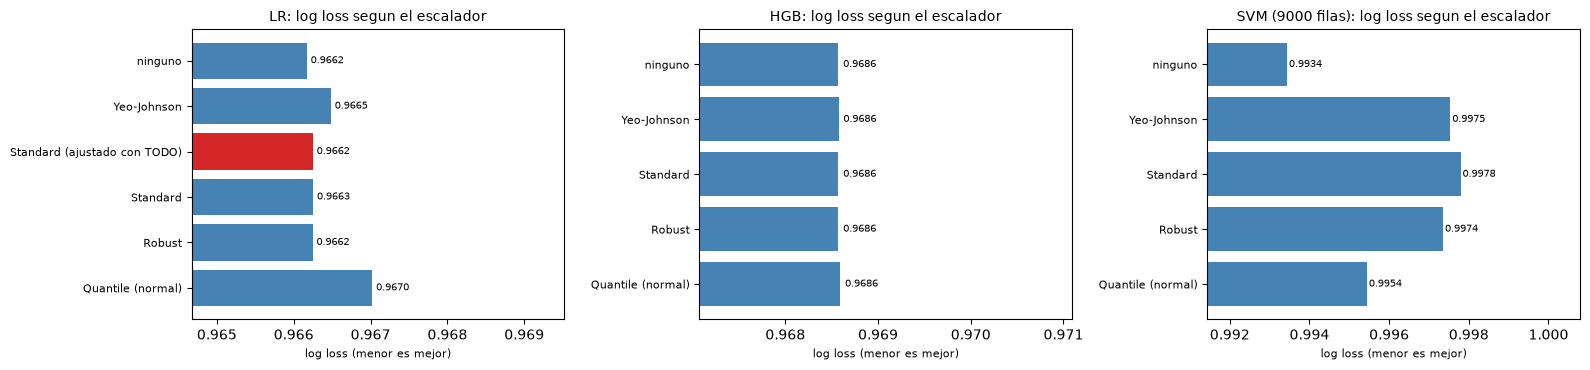

HGB: maxima diferencia entre escaladores = 2.0529391229540117e-05 | LR: Standard en pipeline vs ajustado con TODO el dataset (delta): -3.5e-06


In [3]:
X1 = df[F1].to_numpy(float)
ESC = {'ninguno': lambda: FunctionTransformer(), 'Standard': StandardScaler, 'Robust': RobustScaler,
       'Quantile (normal)': lambda: QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=0), 'Yeo-Johnson': PowerTransformer}
def lr_e(esc): return lambda: make_pipeline(esc(), LogisticRegression(C=1.0, max_iter=5000))
def svm_e(esc): return lambda: make_pipeline(esc(), SVC(C=1.0, gamma='scale', probability=True, random_state=0))
hgb_e = lambda esc: (lambda: make_pipeline(esc(), HistGradientBoostingClassifier(learning_rate=0.05, max_iter=100, max_depth=3, min_samples_leaf=100, random_state=0)))

def cv_cap(fab, X, cap=9000):
    Pm = np.full((len(y), 3), np.nan)
    for s in FOLDS:
        ix = np.where(seas < s)[0][-cap:]; va = seas == s
        Pm[va] = fab().fit(X[ix], y[ix]).predict_proba(X[va])
    return Pm

filas, LOSS_E = [], {}
for nom_e, esc in ESC.items():
    for nom_m, fab, f in (('LR', lr_e, cv_proba), ('HGB', hgb_e, cv_proba), ('SVM (9000 filas)', svm_e, cv_cap)):
        Pm = f(fab(esc), X1); LOSS_E[(nom_m, nom_e)] = loss_vec(Pm)
        filas.append(dict(modelo=nom_m, escalado=nom_e, log_loss=float(np.nanmean(LOSS_E[(nom_m, nom_e)][EV]))))
# estandarizacion ajustada con TODO el dataset (fuga)
Xleak = StandardScaler().fit_transform(X1)
for nom_m, fab, f in (('LR', lambda: LogisticRegression(C=1.0, max_iter=5000), cv_proba),):
    Pm = f(fab, Xleak); LOSS_E[(nom_m, 'Standard (ajustado con TODO)')] = loss_vec(Pm)
    filas.append(dict(modelo=nom_m, escalado='Standard (ajustado con TODO)', log_loss=float(np.nanmean(LOSS_E[(nom_m, 'Standard (ajustado con TODO)')][EV]))))
t2 = pd.DataFrame(filas).pivot(index='escalado', columns='modelo', values='log_loss')
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, m in zip(axs, ['LR', 'HGB', 'SVM (9000 filas)']):
    v = t2[m].dropna(); cols = ['tab:red' if e.startswith('Standard (aj') else 'steelblue' for e in v.index]
    ax.barh(range(len(v)), v.to_numpy(), color=cols); ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index, fontsize=8)
    ax.set_xlim(v.min() - 0.0015, v.max() + 0.0025) if m != 'SVM (9000 filas)' else ax.set_xlim(v.min() - 0.002, v.max() + 0.003)
    for yi, x in enumerate(v): ax.text(x + 0.00005, yi, f'{x:.4f}', va='center', fontsize=7)
    ax.set_title(f'{m}: log loss segun el escalador', fontsize=10); ax.set_xlabel('log loss (menor es mejor)', fontsize=8)
plt.tight_layout(); plt.show()
print('HGB: maxima diferencia entre escaladores =', float(t2['HGB'].max() - t2['HGB'].min()), '| LR: Standard en pipeline vs ajustado con TODO el dataset (delta):', round(comparar(LOSS_E[('LR', 'Standard (ajustado con TODO)')], LOSS_E[('LR', 'Standard')])['delta'], 7))

**Qué encontramos.** Log loss medio (8 folds):

| Escalador | LR | HGB | SVM (9,000 filas) |
|---|---|---|---|
| ninguno | 0.9662 | 0.9686 | 0.9934 |
| Standard (vigente) | 0.9663 | 0.9686 | 0.9978 |
| Robust | 0.9662 | 0.9686 | 0.9974 |
| Quantile (normal) | 0.9670 | 0.9686 | 0.9954 |
| Yeo-Johnson | 0.9665 | 0.9686 | 0.9975 |
| Standard ajustado con TODO el dataset (fuga) | 0.9662 | — | — |

1. **HGB es invariante al escalado:** la diferencia máxima es **2·10⁻⁵** (ruido numérico): la regla de Zheng ("los árboles no necesitan escalar") queda verificada en nuestros datos.
2. **La LR casi no depende del escalador** (rango 0.0008, todos dentro del ruido). F1 mezcla variables de escala parecida (probabilidades, medias de goles y puntos), así que aquí la estandarización no es decisiva.
3. **Ajustar el escalador con todo el dataset (incluido el futuro) cambia el log loss en 3·10⁻⁶** (IC [−0.0000, +0.0000]): la fuga es numéricamente despreciable, pero se evita igual porque en problemas con otras escalas sería real. Los *pipelines* de `04_modelo.ipynb` ajustan el escalador solo con el entrenamiento de cada fold.
4. **El SVM es sensible al escalador** (0.9934–0.9978, rango 0.0044) y paradójicamente rinde mejor **sin** escalar. Pero ese SVM tiene el defecto de `P(D)` del Paso 2 de `07_evaluacion.ipynb`, así que la comparación entre escaladores no es concluyente.

**Qué significa para nuestro caso.** No hace falta preocuparse por el escalador en este problema: da igual cuál se use, y ajustarlo con todos los datos casi no hace daño. Mantenemos la estandarización por la regla general, no porque mejore el resultado.

**Decisión.** Mantener `StandardScaler` dentro del *pipeline* para LR, SVM y MLP, y nada para árboles: es la regla estándar, no daña y se verificó que la fuga no importa. No se afirma que mejore el resultado.

## Paso 3 — Valores faltantes en las estadísticas de partido (F2)

**Qué vamos a hacer.** Las 20 features de tiros, córners, faltas y tarjetas tienen NaN en el 11% de los partidos (la fuente no las publica). Comparar cinco tratamientos sobre el conjunto F2:

| Tratamiento | Descripción |
|---|---|
| **HGB nativo (vigente)** | el árbol decide la rama de los NaN |
| `HGB + mediana` | imputación por mediana del entrenamiento |
| `HGB + mediana + indicador` | mediana y una columna binaria "faltaba" |
| `LR + mediana` | idem para un modelo lineal |
| `LR + mediana + indicador` | idem |
| `F1` (sin esas columnas) | no usarlas |

**Por qué.** El patrón de NaN es estructural (ligas y temporadas en que la fuente no publica) y por eso se decidió no imputar; aquí se comprueba que esa decisión no cuesta precisión. Si el indicador de "faltaba" ayuda, sería señal de temporada/liga (un proxy no deseado).

features F2 con NaN: 20 | filas con algun NaN: 11.0%


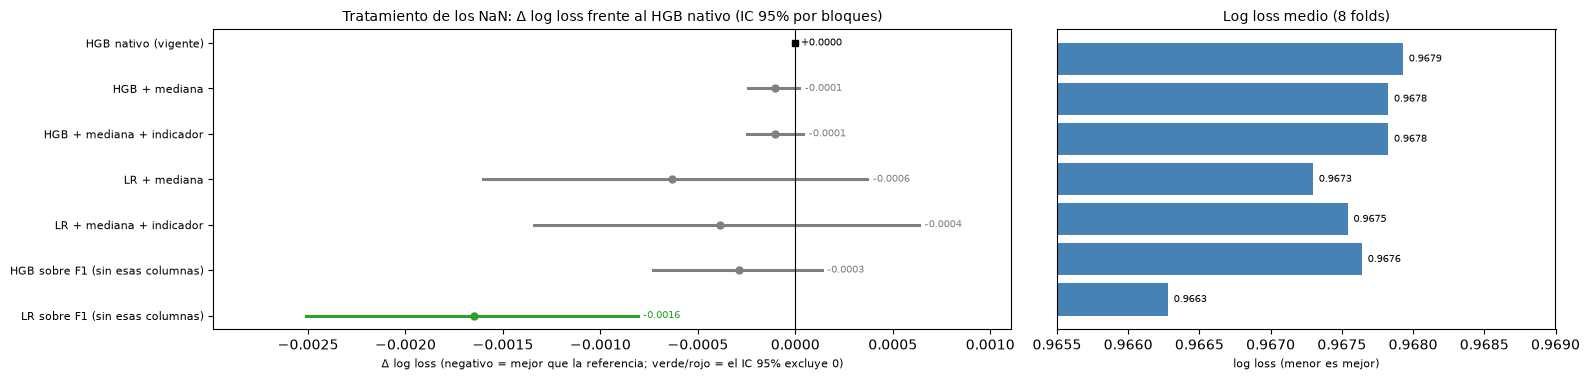

In [4]:
X2 = df[F2].to_numpy(float)
nan_cols = [i for i, f in enumerate(F2) if np.isnan(X2[:, i]).any()]
print('features F2 con NaN:', len(nan_cols), '| filas con algun NaN:', f'{np.isnan(X2).any(1).mean():.1%}')
hgb_f = lambda: HistGradientBoostingClassifier(learning_rate=0.03, max_iter=100, max_depth=2, min_samples_leaf=50, l2_regularization=1.0, random_state=42)
TR = {'HGB nativo (vigente)': (hgb_f, X2),
      'HGB + mediana': (lambda: make_pipeline(SimpleImputer(strategy='median'), hgb_f()), X2),
      'HGB + mediana + indicador': (lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True), hgb_f()), X2),
      'LR + mediana': (lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.05, max_iter=5000)), X2),
      'LR + mediana + indicador': (lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), LogisticRegression(C=0.05, max_iter=5000)), X2),
      'HGB sobre F1 (sin esas columnas)': (hgb_f, X1), 'LR sobre F1 (sin esas columnas)': (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000)), X1)}
LOSS_N = {}; filas = []
for nom, (fab, X) in TR.items():
    LOSS_N[nom] = loss_vec(cv_proba(fab, X)); filas.append(dict(tratamiento=nom, log_loss=float(np.nanmean(LOSS_N[nom][EV]))))
t3 = pd.DataFrame(filas).set_index('tratamiento')
cc = {n: comparar(LOSS_N[n], LOSS_N['HGB nativo (vigente)']) if n != 'HGB nativo (vigente)' else dict(delta=0.0, lo=0.0, hi=0.0) for n in t3.index}
fig, axs = plt.subplots(1, 2, figsize=(16, 3.9), gridspec_kw={'width_ratios': [1.6, 1]})
forest(axs[0], list(t3.index), [cc[n]['delta'] for n in t3.index], [cc[n]['lo'] for n in t3.index], [cc[n]['hi'] for n in t3.index], 'Tratamiento de los NaN: Δ log loss frente al HGB nativo (IC 95% por bloques)')
axs[1].barh(range(len(t3))[::-1], t3.log_loss, color='steelblue'); axs[1].set_xlim(0.9655, 0.9690); axs[1].set_yticks([])
for yi, v in zip(range(len(t3))[::-1], t3.log_loss): axs[1].text(v + 0.00004, yi, f'{v:.4f}', va='center', fontsize=7)
axs[1].set_title('Log loss medio (8 folds)', fontsize=10); axs[1].set_xlabel('log loss (menor es mejor)', fontsize=8)
plt.tight_layout(); plt.show()

**Qué encontramos.** Las 20 features con NaN afectan al 11.0% de las filas.

| Tratamiento | Log loss | Δ vs HGB nativo | IC 95% (bloques) |
|---|---|---|---|
| HGB nativo (vigente) | 0.9679 | — | — |
| HGB + mediana | 0.9678 | −0.0001 | [−0.0002, +0.0000] |
| HGB + mediana + indicador | 0.9678 | −0.0001 | [−0.0002, +0.0001] |
| HGB sobre F1 (sin esas columnas) | 0.9676 | −0.0003 | [−0.0007, +0.0001] |
| LR + mediana | 0.9673 | −0.0006 | [−0.0016, +0.0004] |
| LR + mediana + indicador | 0.9675 | −0.0004 | [−0.0013, +0.0006] |
| **LR sobre F1 (sin esas columnas)** | **0.9663** | **−0.0016** | **[−0.0025, −0.0008]** |

1. **El tratamiento de los NaN no importa para los árboles:** nativo, mediana y mediana + indicador dan lo mismo (Δ ≤ 0.0001), y ninguno se separa de cero. La decisión de no imputar no cuesta precisión.
2. **Para la LR, lo mejor es no usar esas 20 columnas** (F1: −0.0016, IC que excluye 0): las estadísticas de partido añaden ruido y la imputación no lo arregla. Es coherente con el resultado de `04_modelo.ipynb` Paso 2.
3. **El indicador de "faltaba" no ayuda** (+0.0002 frente a solo mediana): no hay señal escondida en el patrón de ausencia más allá de temporada y liga.

**Qué significa para nuestro caso.** Para nuestro problema la mejor forma de tratar las estadísticas ausentes es **no usarlas** en los modelos lineales (el 11% de NaN no lo arregla ninguna imputación) y dejarlas a los árboles. La decisión del EDA de no imputar queda respaldada con números.

**Decisión.** Se confirma la decisión del EDA de **no imputar** (F2 con NaN para árboles) y de **excluir las columnas** en los modelos lineales (F1). Se justifica con evidencia y no solo con el argumento de calidad de datos.

## Paso 4 — Asimetría, transformaciones y valores extremos

**Qué vamos a hacer.**

1. Calcular la **asimetría** (*skewness*) de las features de F2 para decidir si hace falta transformar.
2. Probar, para un modelo lineal sobre F1 + estadísticas imputadas con la mediana, cuatro tratamientos: ninguno, **`log1p`** de los conteos (tiros, córners, faltas, tarjetas), **Yeo–Johnson** (λ por máxima verosimilitud en el entrenamiento) y ***winsorizing*** al percentil 1–99 calculado en el entrenamiento.

**Por qué.** Zheng cap. 2: las colas pesadas se corrigen con log o Box–Cox, pero "nunca confiar en una transformación antes de graficar la entrada contra el target". El EDA ya concluyó que los valores extremos son partidos reales, no errores; aquí se mide si recortarlos o transformarlos mejora algo.

features con |skew| > 1: 1 de 33


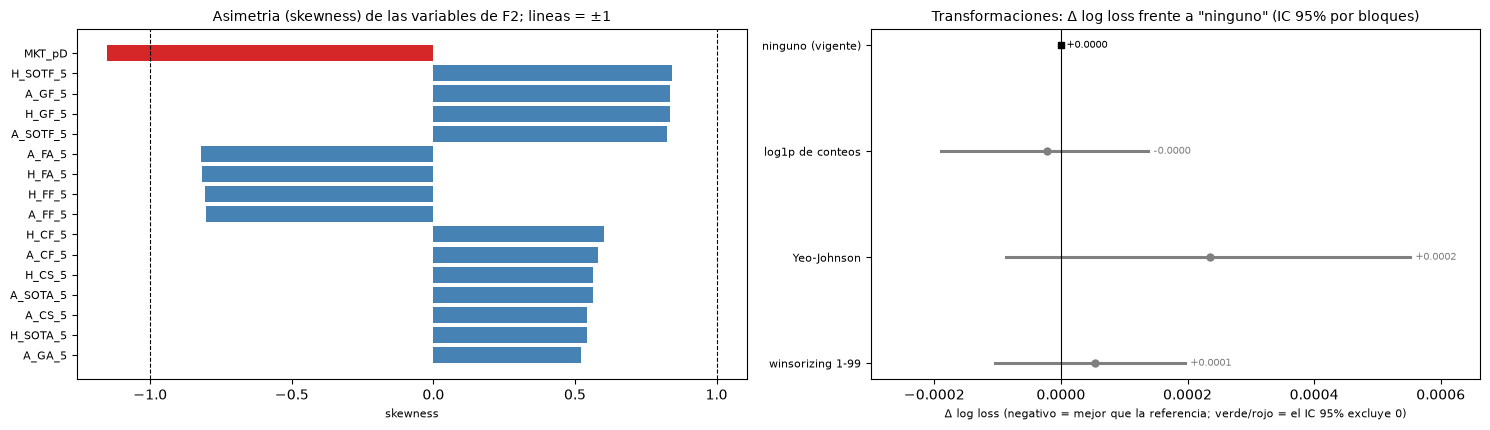

In [5]:
sk = pd.Series(skew(np.nan_to_num(X2, nan=np.nanmedian(X2)), axis=0), index=F2).sort_values(key=np.abs, ascending=False)
print('features con |skew| > 1:', int((sk.abs() > 1).sum()), 'de', len(sk))

CNT = [i for i, f in enumerate(F2) if any(t in f for t in ('SGF', 'SGA', 'SOTF', 'SOTA', '_CF_', '_CA_', '_FF_', '_FA_', 'Card'))]
def log_cnt(X):
    X = X.copy(); X[:, CNT] = np.log1p(np.clip(X[:, CNT], 0, None)); return X
class Wins:
    def __init__(self, lo=1, hi=99): self.lo, self.hi = lo, hi
    def fit(self, X, y=None): self.a, self.b = np.nanpercentile(X, self.lo, 0), np.nanpercentile(X, self.hi, 0); return self
    def transform(self, X): return np.clip(X, self.a, self.b)
    def fit_transform(self, X, y=None): return self.fit(X).transform(X)
    def get_params(self, deep=True): return {'lo': self.lo, 'hi': self.hi}
    def set_params(self, **p): [setattr(self, k, v) for k, v in p.items()]; return self
base = lambda *pre: (lambda: make_pipeline(*pre, SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.05, max_iter=5000)))
TRF = {'ninguno (vigente)': (base(), X2), 'log1p de conteos': (base(), log_cnt(X2)), 'Yeo-Johnson': (base(PowerTransformer()), X2), 'winsorizing 1-99': (base(Wins()), X2)}
LOSS_T = {n: loss_vec(cv_proba(f, X)) for n, (f, X) in TRF.items()}
t4 = pd.DataFrame([dict(tratamiento=n, log_loss=float(np.nanmean(LOSS_T[n][EV]))) for n in TRF]).set_index('tratamiento')
cc4 = {n: comparar(LOSS_T[n], LOSS_T['ninguno (vigente)']) if n != 'ninguno (vigente)' else dict(delta=0.0, lo=0.0, hi=0.0) for n in TRF}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.1, 1]})
top = sk.head(16)[::-1]; axs[0].barh(range(len(top)), top.to_numpy(), color=['tab:red' if abs(v) > 1 else 'steelblue' for v in top]); axs[0].set_yticks(range(len(top))); axs[0].set_yticklabels(top.index, fontsize=8)
axs[0].axvline(1, color='k', ls='--', lw=0.8); axs[0].axvline(-1, color='k', ls='--', lw=0.8); axs[0].set_title('Asimetria (skewness) de las variables de F2; lineas = ±1', fontsize=10); axs[0].set_xlabel('skewness', fontsize=8)
forest(axs[1], list(TRF), [cc4[n]['delta'] for n in TRF], [cc4[n]['lo'] for n in TRF], [cc4[n]['hi'] for n in TRF], 'Transformaciones: Δ log loss frente a "ninguno" (IC 95% por bloques)')
plt.tight_layout(); plt.show()

**Qué encontramos.** Solo **1 de las 33 features** tiene |asimetría| > 1 (`MKT_pD`, −1.15); las de forma están entre −0.82 y +0.84. Ninguna transformación mejora a la LR:

| Tratamiento | Log loss | Δ vs ninguno | IC 95% (bloques) | Folds en que mejora |
|---|---|---|---|---|
| ninguno (vigente) | 0.9673 | — | — | — |
| `log1p` de conteos | 0.9673 | −0.0000 | [−0.0002, +0.0001] | 3/8 |
| Yeo-Johnson | 0.9675 | +0.0002 | [−0.0001, +0.0006] | 3/8 |
| *winsorizing* 1–99 | 0.9674 | +0.0001 | [−0.0001, +0.0002] | 2/8 |

Las medias móviles de 5 partidos ya promedian conteos y quedan casi simétricas, así que no hay colas pesadas que corregir; el resultado es el esperado.

**Qué significa para nuestro caso.** No necesitamos transformar nada: las variables ya están casi simétricas y los valores extremos son partidos reales. Es un preprocesamiento menos que explicar y menos que mantener.

**Decisión.** No transformar ni recortar. Se confirma lo que el EDA decía a ojo: los extremos son partidos reales, no errores, y recortarlos o transformarlos no aporta.

## Paso 5 — Binning y WOE/IV (Siddiqi) frente a variable continua

**Qué vamos a hacer.**

1. Calcular el **valor de información (IV)** de cada feature respecto de "gana el local" (binario), con 10 tramos de igual masa calculados en el entrenamiento (primer 80% de los partidos por fecha) y la clasificación de Siddiqi (IV < 0.02 inútil; 0.02–0.1 débil; 0.1–0.3 medio; 0.3–0.5 fuerte; > 0.5 sospechoso).
2. Comparar, para predecir "gana el local", una **LR sobre `MKT_logit` continuo** frente a una **LR sobre el WOE** de `MKT_logit` (tramos y WOE aprendidos solo con el entrenamiento de cada fold, con suavizado), y lo mismo para el bloque sin cuotas (plantilla + forma).

**Por qué.** Siddiqi cap. 10 construye todo su *scorecard* sobre variables agrupadas con WOE monótono. Si las cuotas ya son lineales en log-odds (`logit`), el binning no debería aportar; el IV además sirve como un ranking alternativo a la información mutua.

conteo de variables por clase de IV: {'debil': 11, 'medio': 11, 'inutil': 9, 'sospechoso': 2, 'fuerte': 0}


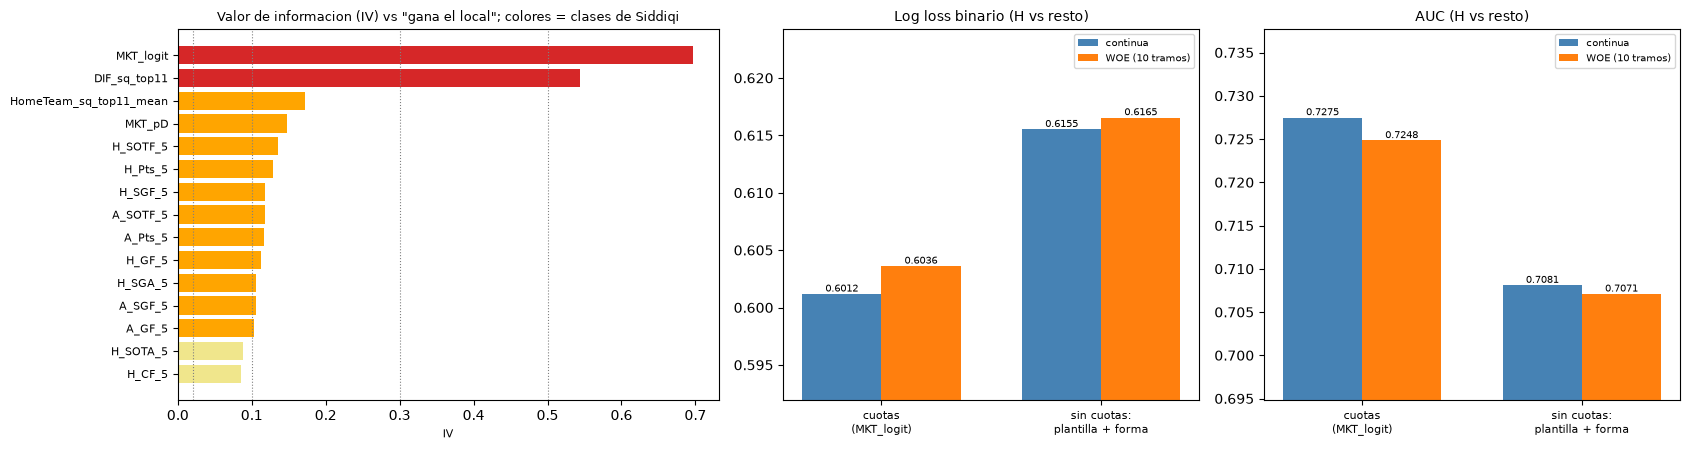

cuotas (MKT_logit): WOE - continua = +0.0024 [+0.0016, +0.0033] | folds en que WOE mejora: 0/8
sin cuotas: plantilla + forma: WOE - continua = +0.0010 [+0.0002, +0.0020] | folds en que WOE mejora: 1/8


In [6]:
yb = (y == 0).astype(int)
def woe_fit(x, yv, nb=10):
    q = np.unique(np.nanquantile(x, np.linspace(0, 1, nb + 1)[1:-1]))
    b = np.digitize(x, q); K = len(q) + 1
    g = np.array([(yv[b == k] == 0).sum() + 0.5 for k in range(K)]); bd = np.array([(yv[b == k] == 1).sum() + 0.5 for k in range(K)])
    return q, np.log((g / g.sum()) / (bd / bd.sum())), (g / g.sum() - bd / bd.sum()) * np.log((g / g.sum()) / (bd / bd.sum()))
def woe_apply(x, q, w): return w[np.digitize(x, q)]

corte = np.quantile(fechas.astype('int64'), 0.8); tr80 = (fechas.astype('int64') <= corte).to_numpy()
iv = {}
for f in F2 + ['DIF_sq_top11']:
    x = df[f].to_numpy(float); m = tr80 & ~np.isnan(x)
    if m.sum() > 500: iv[f] = woe_fit(x[m], yb[m])[2].sum()
iv = pd.Series(iv).sort_values(ascending=False)
clase = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 0.5, 10], labels=['inutil', 'debil', 'medio', 'fuerte', 'sospechoso'])
print('conteo de variables por clase de IV:', clase.value_counts().to_dict())

def cv_bin(cols, usar_woe):
    Pm = np.full(len(y), np.nan)
    for s in FOLDS:
        tr, va = seas < s, seas == s
        if usar_woe:
            Z = np.column_stack([woe_apply(df[c].to_numpy(float), *woe_fit(df.loc[tr, c].to_numpy(float), yb[tr])[:2]) for c in cols])
        else:
            Z = df[cols].to_numpy(float)
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)).fit(Z[tr], yb[tr])
        Pm[va] = m.predict_proba(Z[va])[:, 1]
    return Pm
def ll_bin(Pm):
    o = np.full(len(y), np.nan); ok = ~np.isnan(Pm); o[ok] = -np.log(np.clip(np.where(yb[ok] == 1, Pm[ok], 1 - Pm[ok]), 1e-9, 1)); return o
filas = []; LB = {}
for nom, cols in (('cuotas (MKT_logit)', ['MKT_logit']), ('sin cuotas: plantilla + forma', SQ + FORMA)):
    for tipo in (False, True):
        Pm = cv_bin(cols, tipo); k = (nom, 'WOE (10 tramos)' if tipo else 'continua'); LB[k] = ll_bin(Pm)
        filas.append(dict(conjunto=nom, representacion=k[1], log_loss_binario=float(np.nanmean(LB[k][EV])), AUC=roc_auc_score(yb[EV], Pm[EV])))
t5 = pd.DataFrame(filas)
colores = {'inutil': 'lightgray', 'debil': 'khaki', 'medio': 'orange', 'fuerte': 'tab:green', 'sospechoso': 'tab:red'}
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
top = iv.head(15)[::-1]; axs[0].barh(range(len(top)), top.to_numpy(), color=[colores[str(clase[k])] for k in top.index]); axs[0].set_yticks(range(len(top))); axs[0].set_yticklabels(top.index, fontsize=8)
for x_, lab in ((0.02, 'debil'), (0.1, 'medio'), (0.3, 'fuerte'), (0.5, 'sospechoso')): axs[0].axvline(x_, color='gray', ls=':', lw=0.8)
axs[0].set_title('Valor de informacion (IV) vs "gana el local"; colores = clases de Siddiqi', fontsize=9); axs[0].set_xlabel('IV', fontsize=8)
for ax, met, tit in ((axs[1], 'log_loss_binario', 'Log loss binario (H vs resto)'), (axs[2], 'AUC', 'AUC (H vs resto)')):
    pv = t5.pivot(index='conjunto', columns='representacion', values=met); xs = np.arange(len(pv)); w = 0.36
    ax.bar(xs - w / 2, pv['continua'], w, label='continua', color='steelblue'); ax.bar(xs + w / 2, pv['WOE (10 tramos)'], w, label='WOE (10 tramos)', color='tab:orange')
    ax.set_xticks(xs); ax.set_xticklabels(['cuotas\n(MKT_logit)' if 'cuotas (' in n else 'sin cuotas:\nplantilla + forma' for n in pv.index], fontsize=8)
    lo_, hi_ = pv.to_numpy().min(), pv.to_numpy().max(); ax.set_ylim(lo_ - (hi_ - lo_) * 0.6, hi_ + (hi_ - lo_) * 0.5)
    for i_, n in enumerate(pv.index):
        ax.text(i_ - w / 2, pv.loc[n, 'continua'], f"{pv.loc[n, 'continua']:.4f}", ha='center', va='bottom', fontsize=7); ax.text(i_ + w / 2, pv.loc[n, 'WOE (10 tramos)'], f"{pv.loc[n, 'WOE (10 tramos)']:.4f}", ha='center', va='bottom', fontsize=7)
    ax.set_title(tit, fontsize=10); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
for nom in t5.conjunto.unique():
    c = comparar(LB[(nom, 'WOE (10 tramos)')], LB[(nom, 'continua')])
    print(f'{nom}: WOE - continua = {c["delta"]:+.4f} {c["ic"]} | folds en que WOE mejora: {c["folds_mejora"]}')

**Qué encontramos.** *Valor de información* respecto de "gana el local" (primer 80% de los partidos):

| Feature | IV | Clase (Siddiqi) |
|---|---|---|
| `MKT_logit` | 0.697 | > 0.5 "sospechoso" |
| `DIF_sq_top11` | 0.543 | > 0.5 "sospechoso" |
| `HomeTeam_sq_top11_mean` | 0.173 | medio |
| `MKT_pD` | 0.148 | medio |
| `H_SOTF_5`, `H_Pts_5`, `H_SGF_5` | 0.12–0.14 | medio |

Conteo: 2 sospechosas, 0 fuertes, 11 medias, 11 débiles, 9 inútiles. **En un scorecard de crédito un IV > 0.5 es señal de variable "demasiado buena" (posible fuga); aquí es legítimo:** la cuota **es** la estimación del mercado, y la plantilla resume la fuerza del equipo; ninguna de las dos incluye información del resultado del propio partido.

*¿Mejora el binning con WOE?*

| Conjunto | Continua | WOE (10 tramos) | Δ (WOE − continua) | Folds en que WOE mejora |
|---|---|---|---|---|
| Cuotas (`MKT_logit`) | 0.6012 | 0.6036 | **+0.0024** [+0.0016, +0.0033] | 0/8 |
| Plantilla + forma (sin cuotas) | 0.6155 | 0.6165 | +0.0010 [+0.0002, +0.0019] | 1/8 |

El binning **empeora** el resultado de forma consistente (0/8 y 1/8 folds): discretizar en 10 tramos pierde información de una relación que ya es casi lineal en log-odds. Eso es lo esperable cuando la variable ya está en una escala apropiada (`logit`).

**Qué significa para nuestro caso.** El enfoque de scorecard (binning + WOE) está pensado para modelos interpretables sobre variables crudas, y aquí empeora. Nuestras variables clave ya son lineales en log-odds, así que no hay nada que ganar; el IV sí sirve como ranking y confirma que `MKT_logit` y la plantilla son las dos señales fuertes.

**Decisión.** Mantener las variables **continuas**. El binning/WOE de Siddiqi se justifica para variables crudas y no monótonas en un *scorecard* interpretable (puntos por atributo), no para un modelo cuya única entrada fuerte ya es lineal en log-odds. El IV queda como ranking descriptivo complementario a la información mutua.

## Paso 6 — Fuerza de equipo con memoria larga y normalización de la plantilla

**Qué vamos a hacer.** La forma de los últimos 5 partidos es muy ruidosa (`04_modelo.ipynb` Paso 10: casi no supera al prior). Comparar, **sin cuotas** y **con cuotas**, la forma vigente con otras formas de resumir la fuerza de un equipo, todas calculadas solo con partidos estrictamente anteriores (con la temporada 2013/14 de calentamiento). Las variables que propone `02_feature.ipynb` (Pasos 11 a 13) se **cargan** de `dataset_extra.csv`; las alternativas que son solo un experimento se construyen aquí.

| Familia | Variables (diferencia local − visitante) | Origen |
|---|---|---|
| **Ventana de puntos** | media de los últimos N partidos, N ∈ {3, 5, 10, 20} | construida aquí (alternativa) |
| **Forma por localía** | puntos medios de los últimos 5 partidos *como local* (equipo local) y *como visitante* (equipo visitante) (Tammouch: la ventaja local es estructural) | construida aquí (alternativa) |
| **Tasa histórica suavizada** | puntos por partido y diferencia de goles por partido acumulados desde el inicio, con *prior* bayesiano de 10 partidos (el *bin counting* con suavizado de Zheng cap. 5) | construida aquí (alternativa) |
| **EWMA** | media exponencial de puntos y de diferencia de goles, vida media 5 y 10 partidos | `02_feature`, Paso 12 |
| **Elo** | rating por liga con ventaja local, multiplicador por diferencia de goles y regresión a la media entre temporadas | `02_feature`, Paso 12 |
| **Plantilla normalizada** | `top11_mean` en z-score dentro de cada liga-temporada | `02_feature`, Paso 11 |

**Evaluación.** Dos preguntas: (a) **sin cuotas**, ¿cuál mejora a la forma de 5 partidos vigente?; (b) **con cuotas**, ¿alguna aporta sobre el mercado? Siempre LR estandarizada y validación temporal.

In [7]:
ms2 = pd.read_csv(DATA + 'matches_clean.csv', usecols=['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR'])
wu = pd.read_csv(DATA + 'matches_warmup.csv', usecols=['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR'])
mm = pd.concat([wu.assign(w=1, rid=-1), ms2.assign(w=0, rid=np.arange(len(ms2)))], ignore_index=True)
mm['dt'] = pd.to_datetime(mm['Date'], dayfirst=True, format='mixed')
mm = mm.sort_values(['dt', 'w', 'rid'], ascending=[True, False, True]).reset_index(drop=True)
mm['seq'] = np.arange(len(mm))
mm['pH'] = np.select([mm.FTR == 'H', mm.FTR == 'D'], [3, 1], 0); mm['pA'] = np.select([mm.FTR == 'A', mm.FTR == 'D'], [3, 1], 0)

# alternativas de ventana que NO se exportan en 02_feature (se prueban aqui): ventanas fijas, forma por localia, tasa historica suavizada
lg = pd.concat([mm.assign(Team=mm.HomeTeam, loc=1, pts=mm.pH, gf=mm.FTHG, ga=mm.FTAG), mm.assign(Team=mm.AwayTeam, loc=0, pts=mm.pA, gf=mm.FTAG, ga=mm.FTHG)], ignore_index=True)
lg['gd'] = lg.gf - lg.ga; lg = lg.sort_values(['Team', 'seq']).reset_index(drop=True)
g = lg.groupby('Team')
for N in (3, 5, 10, 20):
    lg[f'ROLL{N}'] = g['pts'].transform(lambda s: s.shift(1).rolling(N, min_periods=1).mean())
lg['VEN5'] = lg.groupby(['Team', 'loc'])['pts'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
A_ = 10
for col, nom in (('pts', 'HPPG'), ('gd', 'HGDG')):
    cs = g[col].transform(lambda s: s.shift(1).cumsum()).fillna(0); n = g[col].transform(lambda s: s.shift(1).expanding().count()).fillna(0)
    prior = lg[col].mean() if col == 'pts' else 0.0
    lg[nom] = (cs + A_ * prior) / (n + A_)
keycols = ['Season', 'Date', 'HomeTeam', 'AwayTeam']
ALT = [c for c in lg.columns if c.startswith(('ROLL', 'VEN', 'HPPG', 'HGDG'))]
H = lg[lg['loc'] == 1].set_index(['rid'])[ALT].add_prefix('H_'); A = lg[lg['loc'] == 0].set_index(['rid'])[ALT].add_prefix('A_')
HA = H.join(A, how='inner'); HA = HA[HA.index >= 0]
base_ids = ms2[keycols].reset_index().rename(columns={'index': 'rid'}).set_index('rid')
Fd = df[keycols].merge(base_ids.join(HA).reset_index(drop=True), on=keycols, how='left', validate='one_to_one')
assert len(Fd) == len(df)
NEW = pd.DataFrame(index=df.index)
for N in (3, 5, 10, 20): NEW[f'ROLL{N}_DIF'] = Fd[f'H_ROLL{N}'] - Fd[f'A_ROLL{N}']
NEW['VEN5_DIF'] = Fd['H_VEN5'] - Fd['A_VEN5']; NEW['HPPG_DIF'] = Fd['H_HPPG'] - Fd['A_HPPG']; NEW['HGDG_DIF'] = Fd['H_HGDG'] - Fd['A_HGDG']

# variables propuestas en 02_feature (Pasos 11-13): se CARGAN, no se vuelven a construir
EXTRA = pd.read_csv(DATA + 'dataset_extra.csv')
assert (EXTRA[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
for c in ('EWP5_DIF', 'EWP10_DIF', 'EWG5_DIF', 'EWG10_DIF', 'ELO_DIF', 'SQz_H', 'SQz_DIF'): NEW[c] = EXTRA[c].to_numpy()
print('alternativas construidas aqui:', [c for c in NEW.columns if c not in EXTRA.columns]); print('cargadas de dataset_extra:', [c for c in NEW.columns if c in EXTRA.columns])
print('NaN por columna (max):', int(NEW.isna().sum().max()))
NEW = NEW.fillna(NEW.median())

alternativas construidas aqui: ['ROLL3_DIF', 'ROLL5_DIF', 'ROLL10_DIF', 'ROLL20_DIF', 'VEN5_DIF', 'HPPG_DIF', 'HGDG_DIF']
cargadas de dataset_extra: ['EWP5_DIF', 'EWP10_DIF', 'EWG5_DIF', 'EWG10_DIF', 'ELO_DIF', 'SQz_H', 'SQz_DIF']
NaN por columna (max): 274


**Qué encontramos.** Se construyeron aquí **7 alternativas** de ventana (ventanas de 3, 5, 10 y 20 partidos, forma por localía y tasa histórica suavizada), y se **cargaron** de `dataset_extra.csv` las variables propuestas en `02_feature.ipynb`: medias exponenciales de puntos y de diferencia de goles, Elo y plantilla normalizada. Las 14 variables quedan alineadas con `dataset_final.csv` partido a partido.

**Qué significa para nuestro caso.** Las variables que se evalúan son las mismas que se exportaron en `02_feature.ipynb`, no una copia recalculada. La prueba anti-fuga del Elo (alterar 15 resultados y recalcular: el rating previo del partido alterado no cambió en ninguno) y el recálculo a mano de las medias exponenciales están en el Paso 12b de ese cuaderno.

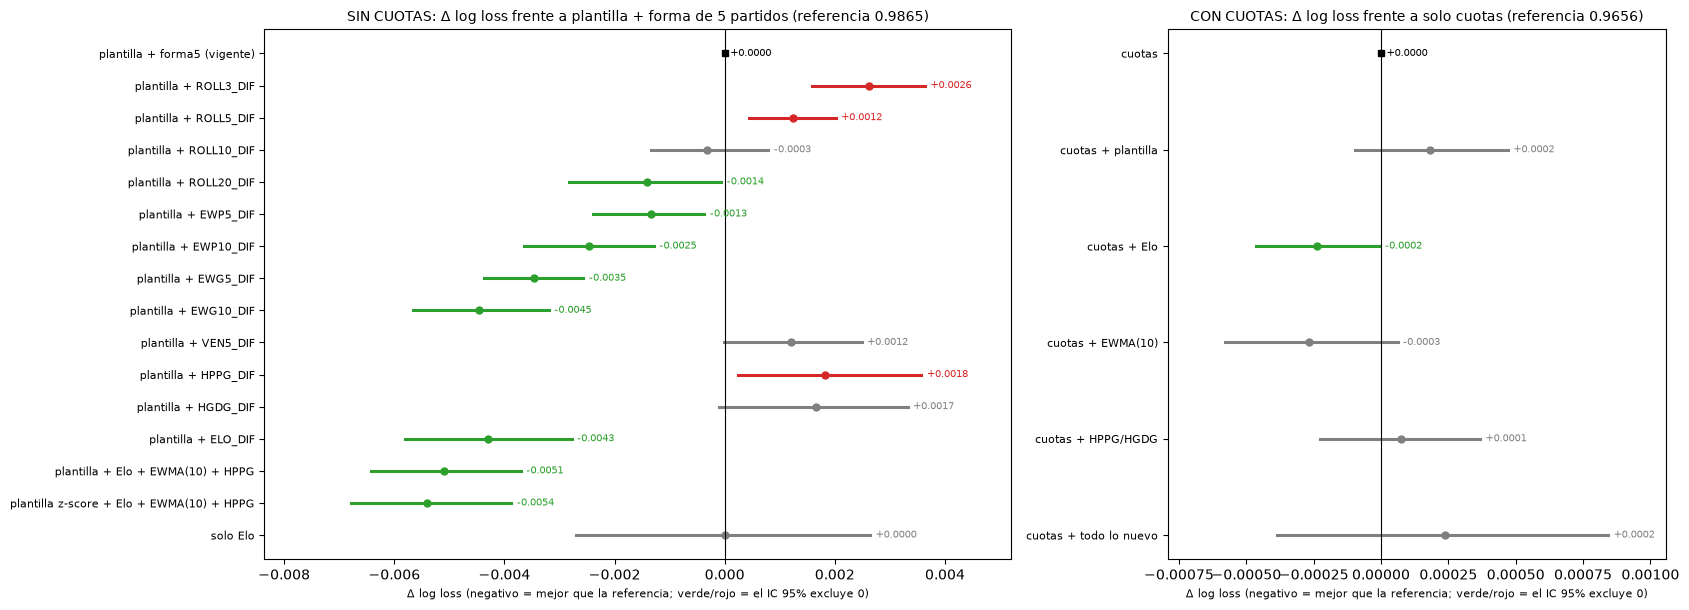

In [8]:
Xb = df.copy(); Xb[list(NEW.columns)] = NEW.to_numpy()
def ev(cols, C=1.0): return loss_vec(cv_proba(lr(C), Xb[cols]))
S0 = SQ + FORMA
CAND_NM = {'plantilla + forma5 (vigente)': S0}
CAND_NM.update({f'plantilla + {k}': SQ + [k] for k in ('ROLL3_DIF', 'ROLL5_DIF', 'ROLL10_DIF', 'ROLL20_DIF', 'EWP5_DIF', 'EWP10_DIF', 'EWG5_DIF', 'EWG10_DIF', 'VEN5_DIF', 'HPPG_DIF', 'HGDG_DIF', 'ELO_DIF')})
CAND_NM['plantilla + Elo + EWMA(10) + HPPG'] = SQ + ['ELO_DIF', 'EWP10_DIF', 'EWG10_DIF', 'HPPG_DIF', 'HGDG_DIF']
CAND_NM['plantilla z-score + Elo + EWMA(10) + HPPG'] = ['SQz_H', 'SQz_DIF', 'ELO_DIF', 'EWP10_DIF', 'EWG10_DIF', 'HPPG_DIF', 'HGDG_DIF']
CAND_NM['solo Elo'] = ['ELO_DIF']
LN = {k: ev(v) for k, v in CAND_NM.items()}
mk_ll = loss_vec(cv_proba(lr(), df[MKT])); pri = np.bincount(y[seas < 1819], minlength=3) / (seas < 1819).sum()
CAND_M = {'cuotas': MKT, 'cuotas + plantilla': MKT + SQ, 'cuotas + Elo': MKT + ['ELO_DIF'], 'cuotas + EWMA(10)': MKT + ['EWP10_DIF', 'EWG10_DIF'],
          'cuotas + HPPG/HGDG': MKT + ['HPPG_DIF', 'HGDG_DIF'], 'cuotas + todo lo nuevo': MKT + list(NEW.columns)}
LM = {k: ev(v) for k, v in CAND_M.items()}
rowsM = []
for k, v in LM.items():
    c = comparar(v, LM['cuotas']) if k != 'cuotas' else dict(delta=0.0, lo=0.0, hi=0.0, folds_mejora='-')
    rowsM.append(dict(conjunto=k, log_loss=float(np.nanmean(v[EV])), delta=c['delta'], lo=c['lo'], hi=c['hi']))
tM = pd.DataFrame(rowsM).set_index('conjunto')
# valores numericos del IC para el grafico sin cuotas
rowsN = []
for k, v in LN.items():
    c = comparar(v, LN['plantilla + forma5 (vigente)']) if k != 'plantilla + forma5 (vigente)' else dict(delta=0.0, lo=0.0, hi=0.0)
    rowsN.append(dict(conjunto=k, delta=c['delta'], lo=c['lo'], hi=c['hi']))
tN = pd.DataFrame(rowsN).set_index('conjunto')
fig, axs = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={'width_ratios': [1.5, 1]})
forest(axs[0], list(tN.index), tN.delta.to_numpy(), tN.lo.to_numpy(), tN.hi.to_numpy(), f'SIN CUOTAS: Δ log loss frente a plantilla + forma de 5 partidos (referencia 0.9865)')
forest(axs[1], list(tM.index), tM.delta.to_numpy(), tM.lo.to_numpy(), tM.hi.to_numpy(), f'CON CUOTAS: Δ log loss frente a solo cuotas (referencia {np.nanmean(mk_ll[EV]):.4f})')
plt.tight_layout(); plt.show()

**Qué encontramos.** *Sin cuotas* (LR; vigente = plantilla + forma de 5 partidos; log loss 0.9865):

| Conjunto | Log loss | Δ vs vigente | IC 95% | Folds |
|---|---|---|---|---|
| plantilla + ROLL3 | 0.9891 | +0.0026 | [+0.0016, +0.0036] | 0/8 |
| plantilla + ROLL5 | 0.9877 | +0.0012 | [+0.0004, +0.0020] | 1/8 |
| plantilla + ROLL10 | 0.9862 | −0.0003 | [−0.0013, +0.0008] | 5/8 |
| plantilla + ROLL20 | 0.9851 | −0.0014 | [−0.0028, −0.0001] | 5/8 |
| plantilla + EWMA puntos (vida media 10) | 0.9840 | −0.0025 | [−0.0036, −0.0013] | 7/8 |
| plantilla + EWMA dif. de goles (vida media 10) | 0.9820 | −0.0045 | [−0.0057, −0.0032] | 7/8 |
| plantilla + **Elo** | 0.9822 | −0.0043 | [−0.0058, −0.0028] | 7/8 |
| plantilla + Elo + EWMA(10) + HPPG | 0.9814 | −0.0051 | [−0.0064, −0.0037] | 7/8 |
| **plantilla z-score + Elo + EWMA(10) + HPPG** | **0.9811** | **−0.0054** | [−0.0068, −0.0039] | 7/8 |

1. **La ventana de 5 partidos era una mala elección:** cuanto más corta, peor (3 partidos: +0.0026; 5: +0.0012 respecto de la vigente que incluye otras 8 variables de forma), y mejora al alargar la memoria (20 partidos: −0.0014).
2. **Las medias exponenciales y el Elo superan claramente a la ventana fija:** el mejor resumen es la **diferencia de goles ponderada exponencialmente** (−0.0045) o el Elo (−0.0043). Una sola variable de Elo con la plantilla iguala o supera a las 8 variables de forma vigentes.
3. **La forma por localía, y la tasa histórica suavizada de puntos, empeoran** (+0.0012 y +0.0018): separar por localía divide la muestra a la mitad y la tasa acumulada desde el inicio tiene demasiada inercia.
4. **Normalizar la plantilla por liga-temporada da una mejora de −0.0003** (0.9814 → 0.9811), dentro del ruido (no se contrastó por separado): el PSI de la plantilla es bajo (0.02–0.12), así que la hipótesis de que los *ratings* de FIFA se inflan con los años **no se confirma** como problema relevante. Se conserva la versión normalizada por ser inocua.

*Con cuotas* (referencia: solo cuotas, 0.9656): ninguna feature nueva mejora de forma distinguible del ruido (Δ entre −0.0003 y +0.0002; todos los IC incluyen 0). `cuotas + Elo` y `cuotas + EWMA(10)` mejoran 0.0002 y 0.0003 en 5/8 y 6/8 folds, pero con IC que toca 0.

**Qué significa para nuestro caso.** Para modelos **sin cuotas** (el benchmark independiente) la memoria larga importa mucho más que la ventana de 5 partidos; para el modelo **con cuotas** no cambia nada porque el precio ya contiene esa información. Es el mismo resultado central del proyecto, ahora comprobado con mejores features: el resultado negativo no se debía a features pobres.

**Decisión.** (a) Para **modelos sin cuotas** (el benchmark independiente de `06_mercado.ipynb`), reemplazar la forma de 5 partidos por **Elo + EWMA de diferencia de goles + plantilla normalizada**: el benchmark mejora **0.0054** de log loss (0.9865 → 0.9811). (b) Para el modelo final con cuotas **no cambia nada**: la información de fuerza de equipo ya está en el precio, que es la misma conclusión central del proyecto, ahora verificada con mejores features. Esto fortalece el resultado negativo: no se debe a haber usado features pobres.

## Paso 6b — ¿Aportan las variables nuevas de `02_feature`?

**Qué vamos a hacer.** Evaluar por grupos todas las variables nuevas, con las dos preguntas del Paso 6:

- **Sin cuotas:** partir de la mejor fuerza de equipo (`SQz`, `ELO_DIF`, `EWG10_DIF`, `EWP10_DIF`) y añadir, en orden, los goles esperados (`XGD`, `TOTXG`), la tendencia al empate (`DRAW_PROP`, `TOTG_PROP`), el contexto (descanso, congestión, recién llegados, semana de temporada) y los tiros a puerta (`SOT10_DIF`, solo árboles porque tiene NaN).
- **Con cuotas:** partir del precio de Pinnacle (`REF_logit`, `REF_pD`) y añadir cada grupo: fuerza, goles esperados y empate, contexto, señales del mercado (`MKT_STD`, `PIN_GAP`), tiros a puerta y **todo** junto.

Se usa regresión logística estandarizada y HGB (HGB con los hiperparámetros conservadores fijos de los Pasos 3 y 4), validación temporal de 8 folds, diferencia pareada con IC por bloques y **corrección de Benjamini–Hochberg** sobre todas las comparaciones de la tabla.

**Por qué.** Es la prueba que decide si alguna de las ideas nuevas merece entrar al modelo final: una variable se queda solo si su mejora, frente a la referencia de su familia, tiene un IC que excluye 0 incluso tras corregir por el número de comparaciones.

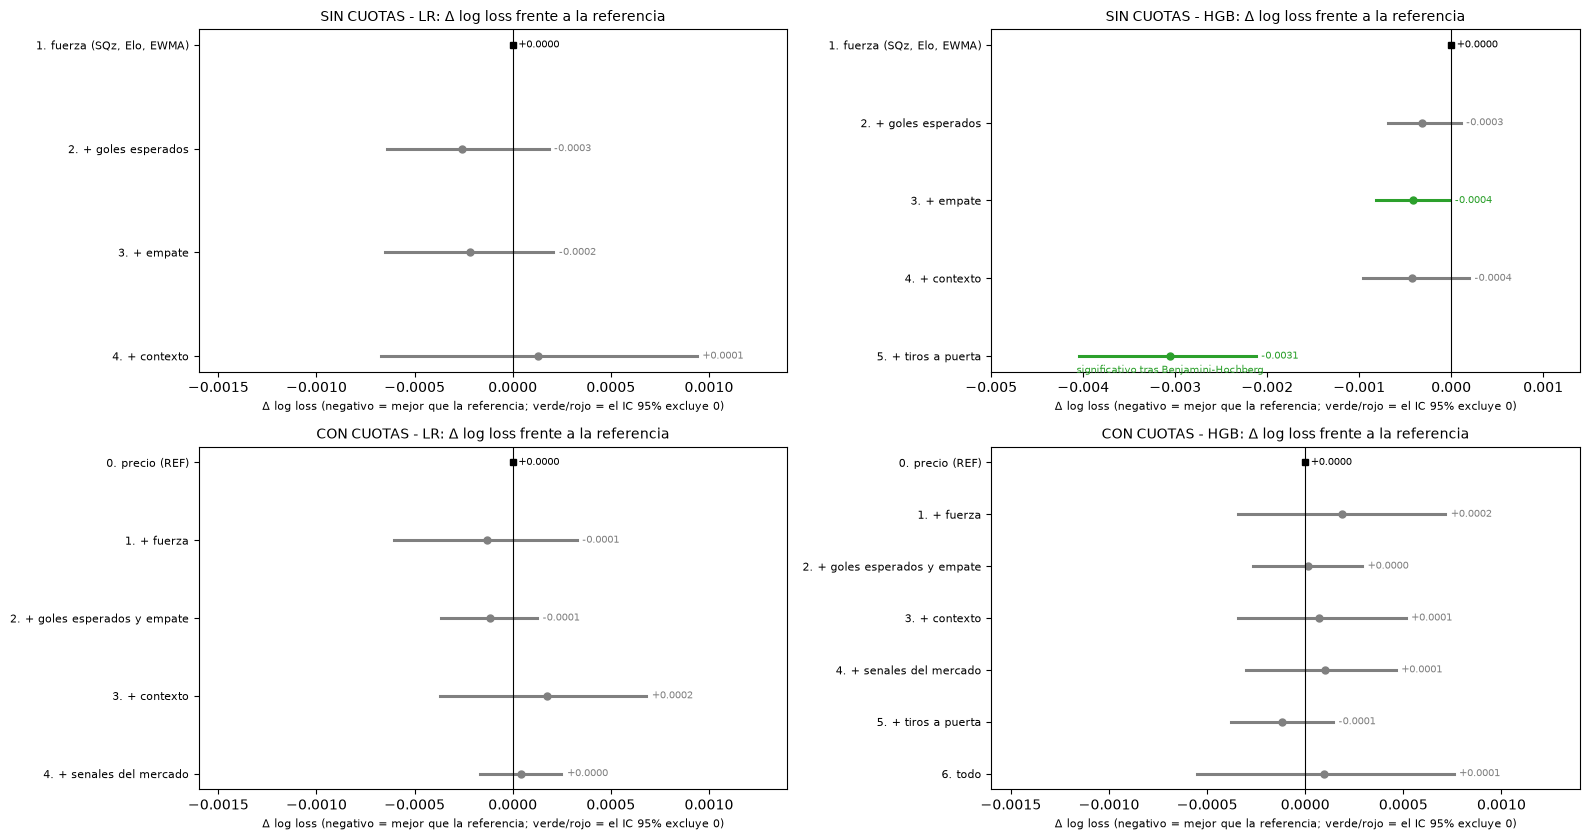

comparaciones: 17 | significativas sin corregir (p<0.05): 2 | tras BH: 1


In [9]:
for c in EXTRA.columns[4:]: Xb[c] = EXTRA[c].to_numpy()
hpH = dict(learning_rate=0.03, max_depth=2, min_samples_leaf=50, max_iter=100)      # HGB conservador, el mismo de los Pasos 3 y 4
hgb_x = lambda: HistGradientBoostingClassifier(learning_rate=hpH['learning_rate'], max_depth=int(hpH['max_depth']), min_samples_leaf=int(hpH['min_samples_leaf']), max_iter=int(hpH['max_iter']), l2_regularization=1.0, random_state=42)
def evm(cols, modelo):
    return loss_vec(cv_proba(lr(1.0) if modelo == 'LR' else hgb_x, Xb[cols]))
FZ = ['SQz_H', 'SQz_DIF', 'ELO_DIF', 'EWG10_DIF', 'EWP10_DIF']; GE = ['XGD', 'TOTXG']; EM = ['DRAW_PROP', 'TOTG_PROP']
CT = ['REST_H', 'REST_A', 'REST_DIF', 'CONG_H', 'CONG_A', 'NEW_H', 'NEW_A', 'SEASON_WEEK']; SOT = ['SOT10_DIF']; MX = ['MKT_STD', 'PIN_GAP']; REF = ['REF_logit', 'REF_pD']
SETS = {'SIN CUOTAS': ({'1. fuerza (SQz, Elo, EWMA)': FZ, '2. + goles esperados': FZ + GE, '3. + empate': FZ + GE + EM, '4. + contexto': FZ + GE + EM + CT, '5. + tiros a puerta': FZ + GE + EM + CT + SOT}, '1. fuerza (SQz, Elo, EWMA)'),
        'CON CUOTAS': ({'0. precio (REF)': REF, '1. + fuerza': REF + FZ, '2. + goles esperados y empate': REF + GE + EM, '3. + contexto': REF + CT, '4. + senales del mercado': REF + MX, '5. + tiros a puerta': REF + SOT, '6. todo': REF + FZ + GE + EM + CT + MX + SOT}, '0. precio (REF)')}
filas = []
for fam, (cands, ref) in SETS.items():
    for modelo in ('LR', 'HGB'):
        L = {}
        for k, cols in cands.items():
            if modelo == 'LR' and any(c in cols for c in SOT + ['SOT10_DIF']): continue
            L[k] = evm(cols, modelo)
        for k in L:
            c = comparar(L[k], L[ref]) if k != ref else dict(delta=0.0, lo=0.0, hi=0.0, ic='-', folds_mejora='-', p=np.nan)
            filas.append(dict(familia=fam, modelo=modelo, conjunto=k, log_loss=float(np.nanmean(L[k][EV])), delta_vs_ref=c['delta'], lo=c['lo'], hi=c['hi'], folds_mejora=c['folds_mejora'], p=c['p']))
t6b = pd.DataFrame(filas)
mk_ = t6b.p.notna(); pp = t6b.loc[mk_, 'p'].to_numpy(); o = np.argsort(pp); mm_ = len(pp); adj = np.empty(mm_); adj[o] = np.minimum.accumulate((pp[o] * mm_ / (np.arange(mm_) + 1))[::-1])[::-1]
t6b.loc[mk_, 'p_BH'] = np.minimum(adj, 1); t6b['signif_BH'] = t6b.p_BH < 0.05
fig, axs = plt.subplots(2, 2, figsize=(16, 8.5))
for r_, fam in enumerate(SETS):
    for c_, modelo in enumerate(('LR', 'HGB')):
        sub_ = t6b[(t6b.familia == fam) & (t6b.modelo == modelo)]
        forest(axs[r_, c_], list(sub_.conjunto), sub_.delta_vs_ref.to_numpy(), sub_.lo.to_numpy(), sub_.hi.to_numpy(), f'{fam} - {modelo}: Δ log loss frente a la referencia')
        for yi, (_, row) in zip(np.arange(len(sub_))[::-1], sub_.iterrows()):
            if row.signif_BH is True or row.get('signif_BH') == True: axs[r_, c_].annotate('significativo tras Benjamini-Hochberg', (row.delta_vs_ref, yi), xytext=(0, -12), textcoords='offset points', ha='center', fontsize=7, color='tab:green')
        axs[r_, c_].set_xlim(-0.0050 if fam == 'SIN CUOTAS' and modelo == 'HGB' else -0.0016, 0.0014)
plt.tight_layout(); plt.show()
print('comparaciones:', int(mk_.sum()), '| significativas sin corregir (p<0.05):', int((t6b.p < 0.05).sum()), '| tras BH:', int(t6b.signif_BH.sum()))

**Qué encontramos.** 17 comparaciones (cada grupo frente a la referencia de su familia); **solo una es significativa tras Benjamini–Hochberg**.

*Sin cuotas* (referencia: fuerza `SQz + Elo + EWMA`, log loss 0.9811):

| Se añade | LR | HGB |
|---|---|---|
| goles esperados (`XGD`, `TOTXG`) | −0.0003 [−0.0006, +0.0002] | −0.0003 [−0.0007, +0.0001] |
| + tendencia al empate | −0.0002 | −0.0004 [−0.0008, −0.0000] (*p* ajustado 0.31) |
| + contexto | +0.0001 | −0.0004 [−0.0010, +0.0002] |
| **+ tiros a puerta (`SOT10_DIF`)** | — (tiene NaN) | **−0.0031 [−0.0040, −0.0021]**, 8/8 folds, *p* ajustado 0.017 |

*Con cuotas* (referencia: `REF_logit` + `REF_pD`; LR 0.9651, HGB 0.9666): ningún grupo mejora de forma distinguible (Δ entre −0.0001 y +0.0002 en LR; entre −0.0001 y +0.0002 en HGB), ni siquiera los tiros a puerta (−0.0001, 6/8 folds). Las señales propias del mercado (`MKT_STD`, `PIN_GAP`) dan 0.0000 (LR) y +0.0001 (HGB), coherente con su inestabilidad (PSI 0.34 y 1.21).

**Qué significa para nuestro caso.** Hay **una variable nueva con información real** —los tiros a puerta ponderados, que miden la calidad del juego con menos azar que los goles—, pero solo sirve cuando no se tiene el precio: con las cuotas, el mercado ya la incorpora (el aporte cae de −0.0031 a −0.0001). El resto de las ideas (goles esperados, empate, descanso, congestión, recién ascendidos, dispersión entre casas) no aporta nada medible, ni sin ni con cuotas. Para el benchmark independiente sin cuotas, `SOT10_DIF` es la mejor adición de todo el proyecto (0.9811 → 0.9781); para el modelo final no cambia nada.

**Decisión.** Para el modelo final con cuotas se mantiene `REF_logit` + `REF_pD`. Para el benchmark sin cuotas, usar fuerza (`SQz`, `ELO_DIF`, `EWG10_DIF`, `EWP10_DIF`) más `SOT10_DIF` con árboles.

## Paso 6c — ¿Plantilla del once titular y normalizada por liga?

**Qué vamos a hacer.** La medida de plantilla de las bases 03/04 (`top11_mean`) es el promedio de los 11 **mejores** jugadores del plantel y no está normalizada por liga. `02_feature.ipynb` (Pasos 10 y 11) construye dos alternativas: el **once titular** de cada club y temporada (`XIz_*`) y la normalización por liga-temporada (`SQz_*`, `XIz_*`). Comparar, con regresión logística y validación temporal:

| Variante de plantilla | Variables |
|---|---|
| `top-11 del plantel` (la vigente) | `DIF_sq_top11`, `HomeTeam_sq_top11_mean` |
| `top-11 normalizado` | `SQz_DIF`, `SQz_H` |
| `once titular normalizado` | `XIz_DIF`, `XIz_H` |
| `ambos` | `SQz_*` y `XIz_*` |

**Dos preguntas.** (a) **Sin cuotas**, junto a la fuerza de equipo (`ELO_DIF`, `EWG10_DIF`, `EWP10_DIF`), ¿mejora usar el once titular y la normalización? (b) **Con cuotas** (`REF_logit`, `REF_pD`), ¿aporta alguna variante?

**Por qué.** Si el once titular describe mejor a quién juega y la normalización quita el nivel propio de cada liga, deberían mejorar la predicción; si no, mantener la medida vigente es lo más simple. Límite de los datos: el once titular es el **por defecto del club en el *snapshot* del juego**, no la alineación de cada partido.

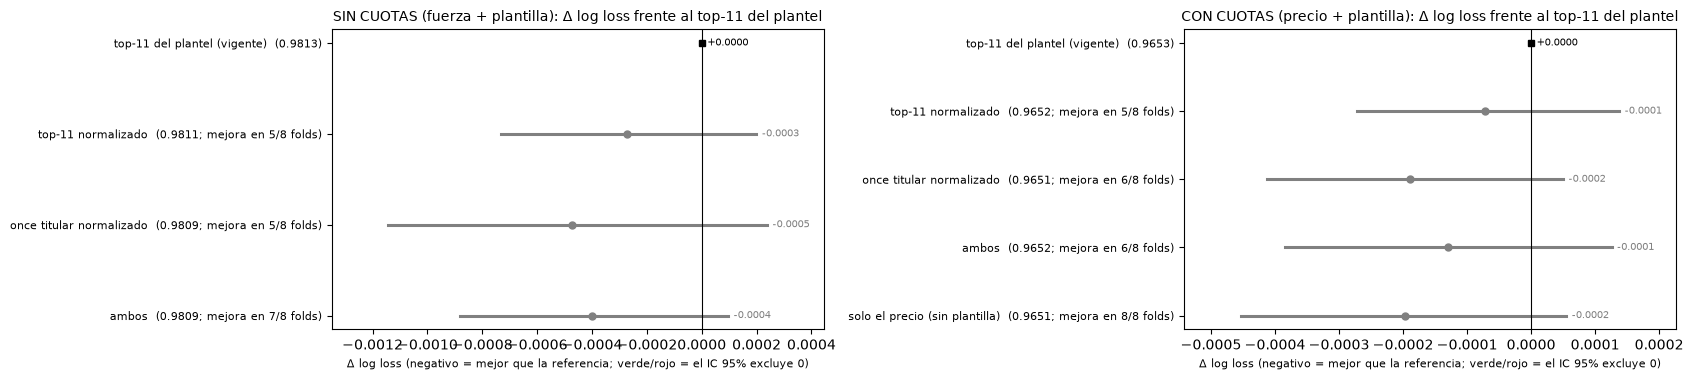

SIN CUOTAS (fuerza + plantilla) {'top-11 del plantel (vigente)': (0.9813, 0.0, (0.0, 0.0), '-'), 'top-11 normalizado': (0.9811, -0.0003, (-0.0007, 0.0002), '5/8'), 'once titular normalizado': (0.9809, -0.0005, (-0.0011, 0.0002), '5/8'), 'ambos': (0.9809, -0.0004, (-0.0009, 0.0001), '7/8')}
CON CUOTAS (precio + plantilla) {'top-11 del plantel (vigente)': (0.9653, 0.0, (0.0, 0.0), '-'), 'top-11 normalizado': (0.9652, -0.0001, (-0.0003, 0.0001), '5/8'), 'once titular normalizado': (0.9651, -0.0002, (-0.0004, 0.0), '6/8'), 'ambos': (0.9652, -0.0001, (-0.0004, 0.0001), '6/8'), 'solo el precio (sin plantilla)': (0.9651, -0.0002, (-0.0005, 0.0001), '8/8')}
correlacion XIz_DIF con SQz_DIF: 0.983 | con DIF_sq_top11: 0.976


In [10]:
PV = {'top-11 del plantel (vigente)': SQ, 'top-11 normalizado': ['SQz_DIF', 'SQz_H'], 'once titular normalizado': ['XIz_DIF', 'XIz_H'], 'ambos': ['SQz_DIF', 'SQz_H', 'XIz_DIF', 'XIz_H']}
FB = ['ELO_DIF', 'EWG10_DIF', 'EWP10_DIF']
RES6C = {}
for fam, base_cols, ref in (('SIN CUOTAS (fuerza + plantilla)', FB, 'top-11 del plantel (vigente)'), ('CON CUOTAS (precio + plantilla)', ['REF_logit', 'REF_pD'], 'top-11 del plantel (vigente)')):
    L = {k: evm(base_cols + v, 'LR') for k, v in PV.items()}
    if fam.startswith('CON'): L['solo el precio (sin plantilla)'] = evm(base_cols, 'LR')
    rows = []
    for k, v in L.items():
        c = comparar(v, L[ref]) if k != ref else dict(delta=0.0, lo=0.0, hi=0.0, folds_mejora='-', p=np.nan)
        rows.append(dict(variante=k, log_loss=float(np.nanmean(v[EV])), delta=c['delta'], lo=c['lo'], hi=c['hi'], folds=c['folds_mejora']))
    RES6C[fam] = pd.DataFrame(rows).set_index('variante')
fig, axs = plt.subplots(1, 2, figsize=(17, 3.9))
for ax, (fam, t_) in zip(axs, RES6C.items()):
    forest(ax, [f'{k}  ({t_.loc[k, "log_loss"]:.4f}; mejora en {t_.loc[k, "folds"]} folds)' if t_.loc[k, 'folds'] != '-' else f'{k}  ({t_.loc[k, "log_loss"]:.4f})' for k in t_.index], t_.delta.to_numpy(), t_.lo.to_numpy(), t_.hi.to_numpy(), f'{fam}: Δ log loss frente al top-11 del plantel')
plt.tight_layout(); plt.show()
for fam, t_ in RES6C.items(): print(fam, {k: (round(r.log_loss, 4), round(r.delta, 4), (round(r.lo, 4), round(r.hi, 4)), r.folds) for k, r in t_.iterrows()})
print('correlacion XIz_DIF con SQz_DIF:', round(float(Xb.XIz_DIF.corr(Xb.SQz_DIF)), 3), '| con DIF_sq_top11:', round(float(Xb.XIz_DIF.corr(Xb.DIF_sq_top11)), 3))

**Qué encontramos.** Ninguna variante de plantilla mejora de forma distinguible del ruido.

| Variante | Sin cuotas (log loss; Δ vs. top-11) | Con cuotas (log loss; Δ vs. top-11) |
|---|---|---|
| top-11 del plantel (vigente) | 0.9813 | 0.9653 |
| top-11 normalizado (`SQz`) | 0.9811; −0.0003 [−0.0007, +0.0002]; 5/8 folds | 0.9652; −0.0001 [−0.0003, +0.0001] |
| **once titular normalizado (`XIz`)** | 0.9809; −0.0005 [−0.0011, +0.0002]; 5/8 folds | 0.9651; −0.0002 [−0.0004, +0.0000]; 6/8 folds |
| ambos | 0.9809; −0.0004 [−0.0009, +0.0001]; 7/8 folds | 0.9652; −0.0001 [−0.0004, +0.0001] |
| solo el precio (sin plantilla) | — | **0.9651**; −0.0002 [−0.0005, +0.0001]; 8/8 folds |

- La medida del once titular es casi idéntica a la del top-11 del plantel (correlación 0.983 entre `XIz_DIF` y `SQz_DIF`, 0.976 con `DIF_sq_top11`).
- Sin cuotas, usar el once titular y normalizar mejora 0.0005 de log loss en estimación puntual, pero el intervalo incluye 0.
- **Con cuotas, quitar la plantilla es tan bueno como cualquier variante** (0.9651): el precio ya la contiene.

**Qué significa para nuestro caso.** Tenía sentido esperar que el once titular y la normalización por liga mejoraran la plantilla, y se probaron las dos cosas; la mejora existe pero es del orden del ruido (0.0003–0.0005 sin cuotas, 0.0001–0.0002 con cuotas). La razón de fondo es que los *ratings* de la plantilla describen la fuerza del equipo, que es lo que el precio ya resume, y que el once por defecto del juego no es la alineación que de verdad juega cada partido. Una medida que sí aportara debería venir de la alineación real de cada partido, información que no está en los datos.

**Decisión.** Para el benchmark **sin cuotas** se usa la plantilla del once titular normalizada (`XIz`), que es la medida más fiel a quién juega y no cuesta nada; para el modelo **final con cuotas** no entra ninguna variante de plantilla.

## Paso 7 — Estabilidad de las variables entre temporadas (PSI, Siddiqi cap. 12)

**Qué vamos a hacer.** Calcular el **índice de estabilidad de la población** (PSI) de cada feature entre el conjunto de entrenamiento de cada fold (todas las temporadas anteriores) y la temporada de validación:

`PSI = Σ (A − E) · ln(A / E)`, con 10 tramos de igual masa definidos en el entrenamiento (E = proporción esperada, A = proporción real). Umbrales de Siddiqi: **< 0.10** estable; **0.10–0.25** investigar; **> 0.25** cambio significativo.

También el PSI de la **probabilidad de victoria local predicha** por la LR sobre cuotas entre folds consecutivos (la "estabilidad del *score*").

**Por qué.** `04_modelo.ipynb` Paso 10 mostró que el *log loss* no se degrada (no hay *concept drift*). El PSI mide algo distinto: si la **distribución de las entradas** cambia (*covariate shift*), por ejemplo porque los *ratings* de FIFA se inflan año tras año.


features con PSI > 0.10 en algun fold: ['MKT_pD', 'MKT_margin', 'SQz_H']
features con PSI > 0.25 en algun fold: ['MKT_margin']



PSI del score (P(H) de la LR sobre cuotas) entre folds consecutivos: {1920: 0.0055, 2021: 0.0207, 2122: 0.0059, 2223: 0.0028, 2324: 0.004, 2425: 0.0096, 2526: 0.0077}


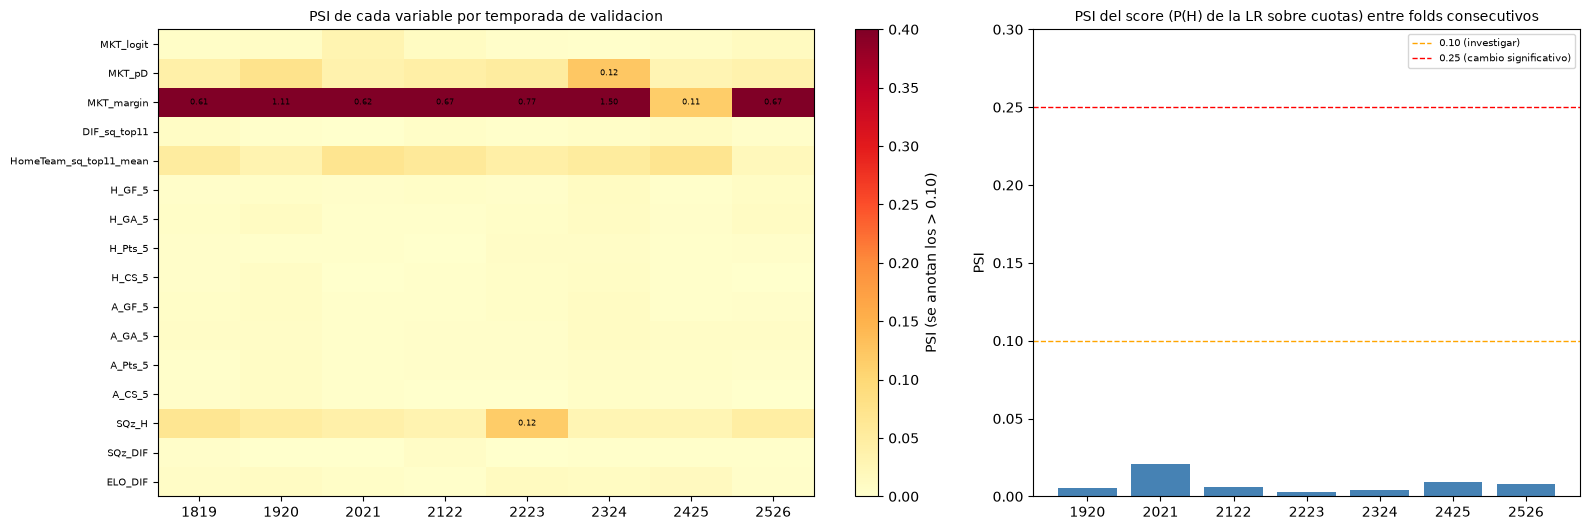

In [11]:
def psi(e, a, nb=10):
    q = np.unique(np.nanquantile(e, np.linspace(0, 1, nb + 1)[1:-1]))
    be, ba = np.digitize(e[~np.isnan(e)], q), np.digitize(a[~np.isnan(a)], q)
    pe = np.clip(np.bincount(be, minlength=len(q) + 1) / len(be), 1e-4, None); pa = np.clip(np.bincount(ba, minlength=len(q) + 1) / len(ba), 1e-4, None)
    return float(np.sum((pa - pe) * np.log(pa / pe)))
cols_psi = MKT + SQ + FORMA + ['SQz_H', 'SQz_DIF', 'ELO_DIF']
Xp = Xb[cols_psi]
ps_tab = pd.DataFrame({int(s): {c: psi(Xp.loc[seas < s, c].to_numpy(float), Xp.loc[seas == s, c].to_numpy(float)) for c in cols_psi} for s in FOLDS})
print('\nfeatures con PSI > 0.10 en algun fold:', list(ps_tab.index[(ps_tab > 0.10).any(axis=1)]))
print('features con PSI > 0.25 en algun fold:', list(ps_tab.index[(ps_tab > 0.25).any(axis=1)]))
P_score = cv_proba(lr(0.05), df[MKT]); pH = P_score[EV, 0]; fo = seas[EV]          # score = P(H) de la LR sobre las 3 variables de mercado (C = 0.05)
print('\nPSI del score (P(H) de la LR sobre cuotas) entre folds consecutivos:', {int(b): round(psi(pH[fo == a], pH[fo == b]), 4) for a, b in zip(FOLDS[:-1], FOLDS[1:])})
score_psi = {int(b): psi(pH[fo == a_], pH[fo == b]) for a_, b in zip(FOLDS[:-1], FOLDS[1:])}
fig, axs = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={'width_ratios': [1.5, 1]})
im = axs[0].imshow(ps_tab.to_numpy(), aspect='auto', cmap='YlOrRd', vmin=0, vmax=0.4)
axs[0].set_xticks(range(len(FOLDS))); axs[0].set_xticklabels([int(s_) for s_ in FOLDS]); axs[0].set_yticks(range(len(cols_psi))); axs[0].set_yticklabels(cols_psi, fontsize=7)
for i_ in range(ps_tab.shape[0]):
    for j_ in range(ps_tab.shape[1]):
        v = ps_tab.iloc[i_, j_]
        if v > 0.1: axs[0].text(j_, i_, f'{v:.2f}', ha='center', va='center', fontsize=6, color='black')
fig.colorbar(im, ax=axs[0], label='PSI (se anotan los > 0.10)'); axs[0].set_title('PSI de cada variable por temporada de validacion', fontsize=10)
axs[1].bar([str(k) for k in score_psi], list(score_psi.values()), color='steelblue'); axs[1].axhline(0.10, color='orange', ls='--', lw=1, label='0.10 (investigar)'); axs[1].axhline(0.25, color='red', ls='--', lw=1, label='0.25 (cambio significativo)')
axs[1].set_ylim(0, 0.3); axs[1].set_title('PSI del score (P(H) de la LR sobre cuotas) entre folds consecutivos', fontsize=10); axs[1].legend(fontsize=7); axs[1].set_ylabel('PSI')
plt.tight_layout(); plt.show()

**Qué encontramos.** PSI por feature y temporada de validación (entrenamiento = todo el pasado):

| Feature | PSI máximo | Lectura |
|---|---|---|
| `MKT_margin` | **1.50** (mediana 0.67) | **cambio significativo** (> 0.25) en 7 de 8 folds (0.115 en 2024/25) |
| `MKT_pD` | 0.122 (2023/24) | investigar solo en un fold |
| `SQz_H` | 0.117 (2022/23) | investigar solo en un fold |
| `HomeTeam_sq_top11_mean` | 0.070 | estable |
| `MKT_logit`, `DIF_sq_top11`, `ELO_DIF` | ≤ 0.030 | estables |
| las 12 features de forma | ≤ 0.012 | muy estables |

Estabilidad del *score* (`P(H)` de la LR sobre cuotas entre folds consecutivos): PSI entre 0.003 y 0.021: **estable** (< 0.10).

1. **Una sola variable viola la estabilidad: `MKT_margin`.** El margen de las casas ha ido bajando con los años (competencia), así que su distribución se desplaza cada temporada. Es una variable de **tiempo** disfrazada, que no aporta información sobre el partido y que se puede aprender como "año". Es consistente con el Paso 1 (quitarla mejora levemente).
2. **Todo lo demás es estable**: la información que importa (`MKT_logit`, la fuerza del equipo) no cambia de distribución entre temporadas, lo que complementa el resultado de que no hay *concept drift* (`04_modelo.ipynb` Paso 10): ni cambia la relación entrada-salida **ni** la distribución de las entradas.
3. El *score* final de la LR es estable (PSI ≤ 0.021), así que el modelo puede usarse temporada tras temporada sin recalibrar.

**Qué significa para nuestro caso.** El único problema de estabilidad está en una variable que no aporta nada sobre el partido (`MKT_margin`); el resto, y el score del modelo, son estables entre temporadas. Eso nos permite usar el modelo temporada tras temporada sin recalibrarlo, y sustenta quitar el margen en el modelo final.

**Decisión.** Sacar `MKT_margin` del conjunto de variables de mercado del modelo final (queda `MKT_logit` y `MKT_pD`). El PSI máximo del resto es < 0.25 en todos los folds, por lo que no se requiere ninguna otra acción.

## Resumen de decisiones de preprocesamiento

| Decisión | Alternativas probadas | Veredicto | Cambio |
|---|---|---|---|
| Cuotas → probabilidad | cuotas crudas, 1/o, proporcional, potencia, logit | Convertir a probabilidad es clave (+0.0054 las crudas); la forma exacta no importa | Ninguno |
| Consenso vs. casa individual | B365, Pinnacle, consenso | Pinnacle (sin margen) −0.0005 mejor; consenso cubre 100% | **Opcional**: Pinnacle con consenso de respaldo |
| `MKT_margin` | con y sin | Variable no estacionaria (PSI 0.6–1.5); quitarla no daña | **Quitarla** en el modelo final |
| Escalado | 5 escaladores × 3 modelos | Irrelevante para LR y HGB; fuga de escalador despreciable | Ninguno (se mantiene la regla) |
| Faltantes | nativo, mediana, mediana + indicador, excluir | Irrelevante para árboles; excluir es mejor para la LR | Ninguno (confirma F1/F2) |
| Transformaciones y extremos | log1p, Yeo–Johnson, winsorizing | Ninguna ayuda (1 de 33 features con |skew| > 1) | Ninguno |
| Binning / WOE | 10 tramos con WOE | Empeora (0/8 folds) | Ninguno (se mantienen continuas) |
| Memoria de la forma | ventanas 3/5/10/20, EWMA, Elo, por localía | 5 partidos era mala elección; EWMA(goles) y Elo −0.0045 | **Sin cuotas**: Elo + EWMA + plantilla z (−0.0054) |
| Con cuotas | cada variable nueva (fuerza, goles esperados, empate, contexto, señales del mercado, tiros a puerta) | Ninguna aporta (IC incluye 0) | Ninguno |
| Variables nuevas sin cuotas | goles esperados, empate, contexto, tiros a puerta (17 comparaciones con Benjamini–Hochberg) | Solo `SOT10_DIF` aporta (−0.0031, 8/8 folds, *p* ajustado 0.017) | **Sin cuotas**: agregar `SOT10_DIF` (árboles) |
| Plantilla: once titular y normalización por liga | top-11 del plantel, top-11 normalizado, once titular normalizado, ambos | Mejoras de 0.0003–0.0005 sin cuotas con IC que incluye 0; con cuotas, ninguna supera a no usar plantilla | **Sin cuotas**: `XIz`; con cuotas, ninguna |
| Estabilidad | PSI por feature y *score* | Todo estable salvo `MKT_margin` (y `PIN_GAP`, `MKT_STD`, `SEASON_WEEK`, vistas en `02_feature`) | Quitar `MKT_margin` |

**Cómo se eligió cada preprocesamiento:** (1) por **leakage** (lo que no se conoce antes del partido se elimina; se verificó con recálculo independiente y con prueba de perturbación); (2) por **calidad de datos** (el patrón de NaN es de la fuente); (3) por **regla de la literatura** (escalado, `shift`, no usar cierre) que aquí se **verificó** y en varios casos resultó irrelevante para el resultado; y (4) por **evidencia empírica** con validación temporal, IC por bloques y la regla de aceptar una alternativa solo si mejora de forma consistente.